# Эксперимент 2. Слить редкие OldCase: X

Вариант «категории × 2», поиск способов поднять precision моделей.

**Идея.** У части состояний `OldCase: X` очень мало событий (от 1 до ~200). Они почти не влияют на граф, но каждое
добавляет узел, вокруг которого модель разрешает лишние переходы. Здесь все `OldCase: X` с числом событий
меньше `MIN_EVENTS = 300` сливаются в одно состояние **`OldCase: Other`** (новые категории не трогаются).

**Зачем.** Проверить, сколько precision теряется из-за редких состояний. Ожидаемо остаётся около 22 состояний.

**Цена.** Для редких категорий пропадает различие «старое дело Sex / Weapon / …».

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Вход — таблица этапа 0
(`jupyter lab\stage0 - data\out\compas_custody_charges.csv`), общий код журнала — `x2_common.py` рядом (тот же, что в
`oldcase_x2`). Результаты пишутся в `out\` этой папки.

**Как сравниваются модели.** Как в `oldcase_x2`: люди делятся на train 80% / test 20% (seed 42), модели строятся на
train, fitness и precision считаются token-based replay на первых 2 000 людях train и test. Базовая линия — вариант
`oldcase_x2` (29 состояний, порядок по тяжести): HM 0.9 — fitness 0.982, precision 0.543; IM 0.2 — 0.994 / 0.383.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import x2_common as X

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
CANDIDATES = [ROOT / "stage0 - data" / "out" / "compas_custody_charges.csv",
              ROOT / "stage0-data" / "compas_custody_charges.csv"]
DATA = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

EXP = "x2_exp2_merge_rare"
BUILD = {}       # параметры журнала
MERGE_RARE = True      # слить редкие OldCase: X
MIN_EVENTS = 300            # порог «редкого» состояния
MODELS = ['HM_0.5', 'HM_0.9', 'HM_0.95', 'IM_0.2', 'IM_0.5']
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
RUN_ILP = False             # ILP Miner (долго)
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 на стольких людях из test (0 — не считать);
                            # чем меньше выборка, тем ниже precision (часть префиксов не встречается), поэтому 2000
print("pm4py", pm4py.__version__, "| вход:", DATA, DATA.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    PILImage.MAX_IMAGE_PIXELS = None
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=80)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | вход: /tmp/claude-0/w/exproot/stage0 - data/out/compas_custody_charges.csv True


## Шаг 1. Журнал событий

In [2]:
ch, ep = X.load(DATA)
merge_old = ()
if MERGE_RARE:
    base_ev, _, _ = X.build("x2", ch, ep, **{k: v for k, v in BUILD.items() if k != "merge_old"})
    vc = base_ev["concept:name"].value_counts()
    merge_old = sorted(a for a, n in vc.items() if a.startswith(X.OLD_PREFIX) and n < MIN_EVENTS)
    print("сливаются в «OldCase: Other»:", ", ".join(f"{a} ({vc[a]})" for a in merge_old))
ev, st, info = X.build("x2", ch, ep, merge_old=merge_old, **BUILD)
info

сливаются в «OldCase: Other»: OldCase: Conspiracy (23), OldCase: Justice (47), OldCase: Minors (19), OldCase: Other (1), OldCase: PublicOrder (209), OldCase: Sex (103), OldCase: Tampering (151), OldCase: Weapon (195)


{'variant': 'x2',
 'people': 10580,
 'episodes': 21716,
 'justice_steps': 107,
 'steps': 21823,
 'events': 34384,
 'transitions': 11243,
 'people_repeat': 5230,
 'multi_type_steps': 8486,
 'activities': 22,
 'obs_end': '2016-04-19'}

In [3]:
log = pm4py.format_dataframe(ev[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                             case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(log)
traces = st.groupby("id")["state"].agg(" → ".join).value_counts()
stats = pd.Series({"состояний": log["concept:name"].nunique(), "событий": len(log), "шагов": len(st),
                   "дуг DFG": len(dfg), "петель DFG (X→X)": sum(a == b for a, b in dfg),
                   "вариантов трасс": len(traces), "людей с уникальной трассой": int((traces == 1).sum())})
ev.to_csv(OUT / f"event_log_{EXP}.csv", index=False)
stats.to_csv(OUT / "log_stats.csv", header=["value"])
print(log["concept:name"].value_counts().to_string())
stats

concept:name
Violent                  5462
Property                 5048
Drug                     4622
Traffic                  4287
OldCase: Property        2255
OldCase: Drug            2216
ResistPolice             1809
OldCase: Traffic         1378
OldCase: Violent         1261
Fraud                    1193
PublicOrder               868
OldCase: ResistPolice     695
OldCase: Other            691
Unknown                   653
OldCase: Fraud            587
Weapon                    410
Tampering                 407
Sex                       312
Justice                   129
Conspiracy                 53
Minors                     43
Other                       5


состояний                        22
событий                       34384
шагов                         21823
дуг DFG                         394
петель DFG (X→X)                 18
вариантов трасс                3268
людей с уникальной трассой     2787
dtype: int64

## Шаг 2. Граф: DFG (30% путей) и сеть Петри Heuristics Miner 0.9

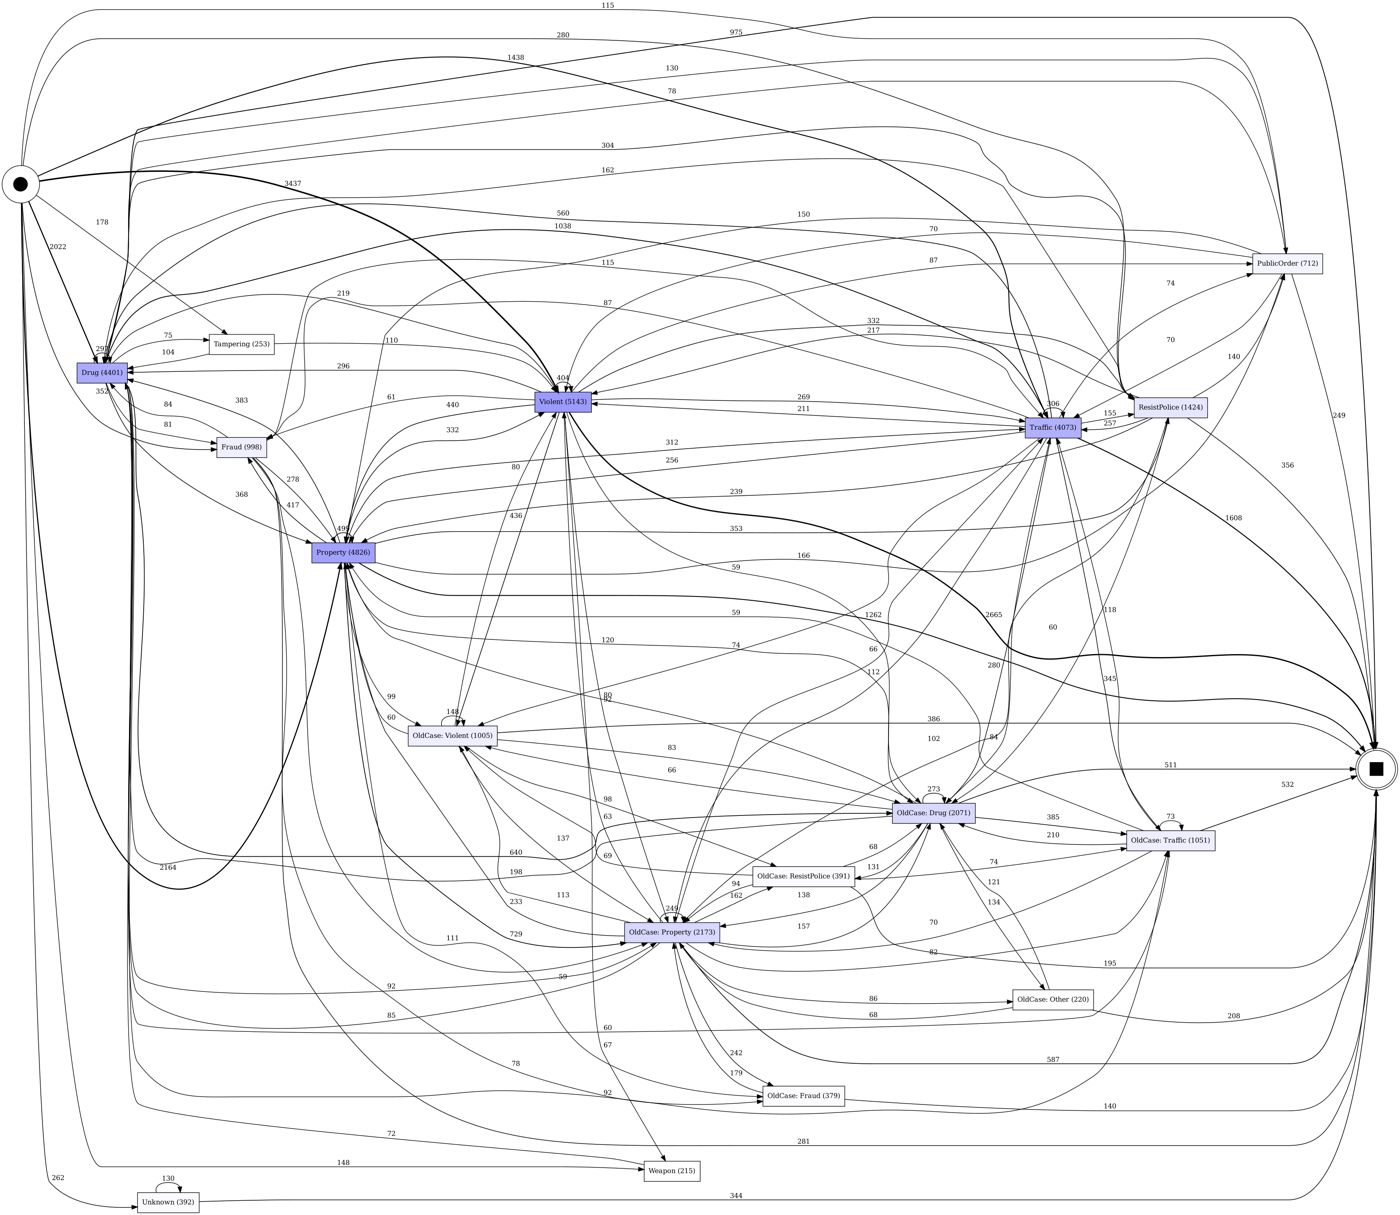

In [4]:
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, sa, ea, 0.3)
# у pm4py 2.7.23.9 рисунок падает, если начальная/конечная активность не осталась ни на одной дуге — убираем такие
acts_f = {a for k in dfg_f for a in k}
sa_f = {a: n for a, n in sa_f.items() if a in acts_f}
ea_f = {a: n for a, n in ea_f.items() if a in acts_f}
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths30.png"))
show(FIG / "dfg_frequency_paths30.png")

HM 0.9 на всём журнале: мест 44, переходов 289


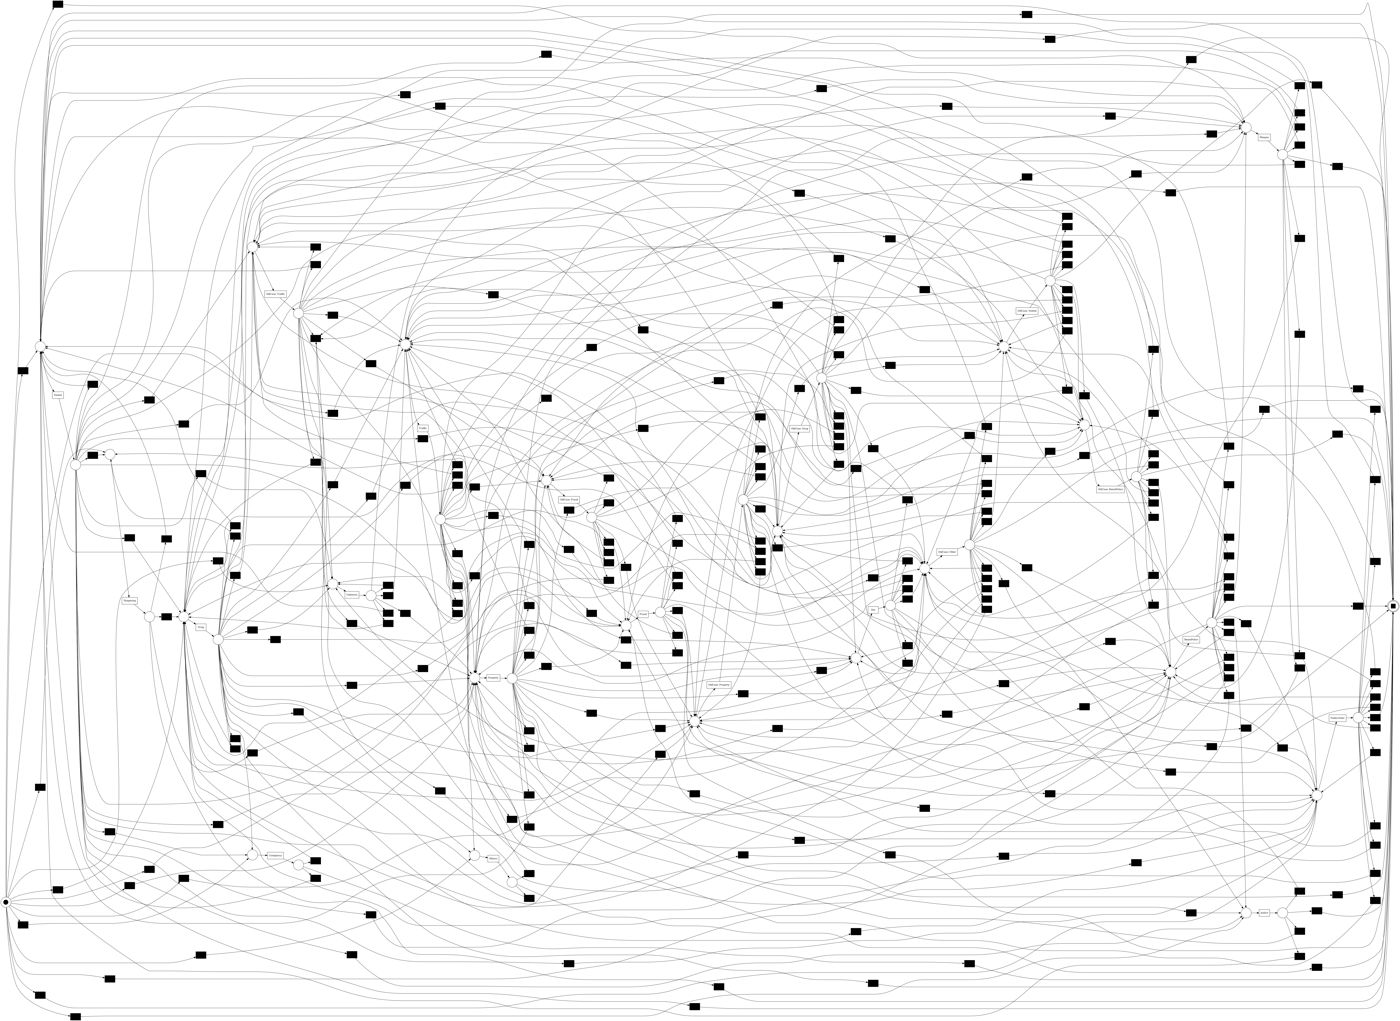

In [5]:
net, im, fm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9 на всём журнале: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

## Шаг 3. Модели и качество

Названия моделей: `HM_d` — Heuristics Miner с порогом зависимости d; `HM_0.9_min30` — то же, дуги реже 30 раз
отбрасываются; `HM_0.9_and0.95` — то же, параллельность (AND) объявляется только при мере ≥ 0.95; `IM_n` — Inductive Miner с порогом шума n; `*_freq` — модель построена только по людям с
трассой, которая встречается хотя бы у двух человек (проверка — на всех); `ILP` — ILP Miner.

In [6]:
train, test = X.split_people(log)
train_s, test_s = X.sample_cases(train, EVAL_CASES), X.sample_cases(test, EVAL_CASES)


def frequent_train():
    # люди из train, чья трасса (последовательность событий) встречается хотя бы у двух человек
    seq = train.groupby("case:concept:name")["concept:name"].agg(tuple)
    n = seq.map(seq.value_counts())
    return train[train["case:concept:name"].isin(n[n >= 2].index)]


def discover(name):
    if name.startswith("HM_"):
        parts = name.split("_")
        lg = frequent_train() if name.endswith("_freq") else train
        kw = dict(dependency_threshold=float(parts[1]))
        if "min30" in name:
            kw["min_dfg_occurrences"] = 30
        return pm4py.discover_petri_net_heuristics(lg, **kw)
    if name.startswith("IM_"):
        lg = frequent_train() if name.endswith("_freq") else train
        return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(name.split("_")[1]))
    if name == "ILP":
        return pm4py.discover_petri_net_ilp(train)
    raise ValueError(name)


models, times = {}, {}
for name in MODELS:
    if name == "ILP" and not RUN_ILP:
        continue
    t0 = time.time()
    models[name] = discover(name)
    times[name] = round(time.time() - t0)
    print(f"{name}: построена за {times[name]} с")

HM_0.5: построена за 1 с


HM_0.9: построена за 0 с


HM_0.95: построена за 0 с
IM_0.2: построена за 0 с


IM_0.5: построена за 0 с


In [7]:
quality = X.evaluate(models, train_s, test_s)
quality["discover_sec"] = quality["model"].map(times)
if ALIGN_CASES and "HM_0.9" in models:
    t0 = time.time()
    pa = pm4py.precision_alignments(X.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
    quality.loc[(quality["model"] == "HM_0.9") & (quality["split"] == "test"), "precision_align"] = round(pa, 4)
    print(f"HM 0.9: precision через выравнивания на {ALIGN_CASES} людях = {pa:.4f} ({time.time() - t0:.0f} с)")
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"]

{'model': 'HM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9367, 'pct_fit_traces': 68.8, 'precision_tbr': 0.591, 'f1': 0.7248, 'places': 91, 'transitions': 316, 'silent': 294, 'sec': 7}


{'model': 'HM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9391, 'pct_fit_traces': 68.5, 'precision_tbr': 0.6376, 'f1': 0.7595, 'places': 91, 'transitions': 316, 'silent': 294, 'sec': 7}


{'model': 'HM_0.9', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9877, 'pct_fit_traces': 91.15, 'precision_tbr': 0.5068, 'f1': 0.6699, 'places': 45, 'transitions': 284, 'silent': 263, 'sec': 8}


{'model': 'HM_0.9', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9871, 'pct_fit_traces': 90.1, 'precision_tbr': 0.5473, 'f1': 0.7042, 'places': 45, 'transitions': 284, 'silent': 263, 'sec': 8}


{'model': 'HM_0.95', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.983, 'pct_fit_traces': 88.8, 'precision_tbr': 0.5217, 'f1': 0.6816, 'places': 44, 'transitions': 262, 'silent': 241, 'sec': 7}


...

{'model': 'IM_0.2', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9587, 'pct_fit_traces': 71.25, 'precision_tbr': 0.4882, 'f1': 0.647, 'places': 74, 'transitions': 104, 'silent': 82, 'sec': 20}


{'model': 'IM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9073, 'pct_fit_traces': 49.2, 'precision_tbr': 0.547, 'f1': 0.6825, 'places': 59, 'transitions': 91, 'silent': 70, 'sec': 7}


{'model': 'IM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9064, 'pct_fit_traces': 49.7, 'precision_tbr': 0.6184, 'f1': 0.7352, 'places': 59, 'transitions': 91, 'silent': 70, 'sec': 7}


HM 0.9: precision через выравнивания на 2000 людях = 0.5473 (28 с)


,model,split,cases,fitness_tbr,pct_fit_traces,precision_tbr,f1,places,transitions,silent,sec,discover_sec,precision_align
1,HM_0.5,test,2000,0.9391,68.50,0.6376,0.7595,91,316,294,7,1,NaN
3,HM_0.9,test,2000,0.9871,90.10,0.5473,0.7042,45,284,263,8,0,0.5473
5,HM_0.95,test,2000,0.9824,88.05,0.5690,0.7206,44,262,241,7,0,NaN
7,IM_0.2,test,2000,0.9587,71.25,0.4882,0.6470,74,104,82,20,0,NaN
9,IM_0.5,test,2000,0.9064,49.70,0.6184,0.7352,59,91,70,7,0,NaN


## Шаг 4. Сравнение с основным вариантом oldcase_x2

In [8]:
BASE = pd.DataFrame({"model": ["HM_0.5", "HM_0.9", "IM_0.0", "IM_0.2", "IM_0.5"],
                     "fitness_base": [0.9415, 0.9821, 1.0, 0.9938, 0.9716],
                     "precision_base": [0.6136, 0.5430, 0.3688, 0.3828, 0.4563]})
cmp = quality[quality["split"] == "test"][["model", "fitness_tbr", "precision_tbr", "f1"]].merge(BASE, on="model", how="left")
cmp["Δ precision"] = (cmp["precision_tbr"] - cmp["precision_base"]).round(4)
cmp.to_csv(OUT / "compare_with_oldcase_x2.csv", index=False)
cmp

,model,fitness_tbr,precision_tbr,f1,fitness_base,precision_base,Δ precision
0,HM_0.5,0.9391,0.6376,0.7595,0.9415,0.6136,0.0240
1,HM_0.9,0.9871,0.5473,0.7042,0.9821,0.5430,0.0043
2,HM_0.95,0.9824,0.5690,0.7206,NaN,NaN,NaN
3,IM_0.2,0.9587,0.4882,0.6470,0.9938,0.3828,0.1054
4,IM_0.5,0.9064,0.6184,0.7352,0.9716,0.4563,0.1621
